# Lab: Quantization and Pruning, Extended

*Modified by Nishit Chaudhary from the course lab (C3_W2_Lab_3).*

This lab trains a small CNN on MNIST and compares **model optimization techniques for edge and mobile deployment**: how much smaller and faster a model gets, and how much accuracy it costs.

It extends the course's *Quantization and Pruning* lab. The original tried one variant of each technique. This version **compares the alternatives within each technique** and measures every result the same way:

| Section | What is compared |
|---|---|
| **A1. Post-training quantization** | dynamic-range int8 (original) vs. float16 vs. full-integer int8 vs. integer-only int8 I/O |
| **A2. Calibration** | how many calibration images full-integer quantization needs |
| **A3. Quantization-aware training** | QAT from untrained weights (original) vs. QAT fine-tuning of the trained model, against PTQ in the same int8 format |
| **B1. Pruning: sparsity sweep** | accuracy and compressed size at 50 / 70 / 80 / 90 / 95% sparsity |
| **B2. Pruning schedules** | `PolynomialDecay` vs. `ConstantSparsity` at 80% |
| **B3. Structured pruning** | hardware-friendly 2:4 sparsity vs. unstructured 50% |
| **C. Pruning + quantization** | prune → PTQ vs. prune → QAT vs. prune → **sparsity-preserving QAT (PQAT)** |
| **D. Results** | one table with accuracy, size, compressed size, measured sparsity and latency for every variant |

The dataset and CNN are deliberately unchanged from the original, so every difference comes from the optimization technique. See `README.md` for setup and a full list of changes.

## Setup

**Versions matter here.** TensorFlow 2.16+ uses Keras 3 by default, but the TensorFlow Model Optimization Toolkit (`tfmot`) only supports Keras 2, so the original notebook crashes at `quantize_model()` on current TensorFlow. The cell below switches TensorFlow to the Keras 2 package (`tf_keras`). This has to happen **before** TensorFlow is imported, so always run this cell first (use *Restart & Run All*).

In [10]:
# Colab only: uncomment, run once, then Runtime > Restart session and re-run from the top.
# !pip install -q tensorflow==2.17.1 tf-keras==2.17.0 tensorflow-model-optimization==0.8.0

import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"   # make tf.keras = Keras 2 (tf_keras), required by tfmot

import tempfile
import time
import zipfile
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import tf_keras as keras
import tensorflow_model_optimization as tfmot

print("TensorFlow:", tf.__version__)
print("Keras:     ", keras.__version__)
print("TF-MOT:    ", getattr(tfmot, "__version__", "installed"))
assert keras.__version__.startswith("2."), "Keras 3 detected: install tf-keras (see README) and restart the kernel."

SEED = 42
BASELINE_EPOCHS = 3
ARTIFACTS = tempfile.mkdtemp(prefix="quant_prune_lab_")   # model files go here, not into the repo
print("Model files are written to:", ARTIFACTS)

TensorFlow: 2.17.1
Keras:      2.17.0
TF-MOT:     0.8.0
Model files are written to: C:\Users\NISHIT\AppData\Local\Temp\quant_prune_lab_p0uucpz8


## Utilities

Every model variant is measured the same way and stored in one `RESULTS` list. The original reset its `ACCURACY` and `MODEL_SIZE` dictionaries three times and mixed raw and compressed sizes, so its variants could never be compared side by side.

- `convert_tflite()` takes a `mode`: `float32`, `dynamic`, `float16`, `int8`, or `int8_io`. The original only supported one quantized mode.
- `evaluate_tflite()` quantizes inputs with the model's own scale and zero-point, so it works for **integer-only** models. The original only handled float inputs.
- `weight_sparsity()` **measures** the fraction of exactly-zero weights. The original only printed raw weight tensors to eyeball.
- `latency_ms()` times single-image inference with the TF Lite interpreter. The original promised lower latency but never measured it.

In [11]:
def path(filename):
    return os.path.join(ARTIFACTS, filename)


def model_builder():
    """Shallow CNN for MNIST (unchanged from the original lab)."""
    return keras.Sequential([
        keras.layers.InputLayer(input_shape=(28, 28)),
        keras.layers.Reshape(target_shape=(28, 28, 1)),
        keras.layers.Conv2D(filters=12, kernel_size=(3, 3), activation="relu"),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Flatten(),
        keras.layers.Dense(10, activation="softmax"),
    ])


def copy_of(model):
    """A fresh model with the same architecture and identical weights."""
    clone = model_builder()
    clone.set_weights(model.get_weights())
    return clone


def compile_model(model, learning_rate=1e-3):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def gzipped_size(file):
    """Size of the file after ZIP (deflate) compression, in bytes. Zeros from pruning compress well."""
    fd, zipped = tempfile.mkstemp(".zip")
    os.close(fd)
    with zipfile.ZipFile(zipped, "w", compression=zipfile.ZIP_DEFLATED) as f:
        f.write(file, arcname=os.path.basename(file))
    size = os.path.getsize(zipped)
    os.remove(zipped)
    return size


def weight_sparsity(model):
    """Fraction of exactly-zero values across all conv/dense kernels, plus a per-layer breakdown."""
    per_layer, zeros, total = {}, 0, 0
    for w in model.weights:
        if w.name.split("/")[-1].split(":")[0] != "kernel":   # skips biases, masks, quantizer ranges
            continue
        values = w.numpy()
        z = int(np.sum(values == 0))
        per_layer[w.name] = round(z / values.size, 4)
        zeros += z
        total += values.size
    return (zeros / total if total else 0.0), per_layer


def representative_dataset(images, n):
    """Calibration data for full-integer quantization: the first n TRAINING images, one at a time."""
    def generator():
        for image in images[:n]:
            yield [image[np.newaxis].astype(np.float32)]
    return generator


def convert_tflite(model, filename, mode="float32", calibration_images=None, n_calibration=100):
    """Convert a Keras model to TF Lite.

    mode:
      float32  - no quantization
      dynamic  - dynamic-range: int8 weights, float activations (the original lab's only mode)
      float16  - float16 weights
      int8     - full-integer: int8 weights AND activations, float input/output
      int8_io  - integer-only: like int8, plus int8 input/output (microcontrollers, Edge TPU)
    PTQ int8 modes calibrate on calibration_images (default: training images). QAT models keep
    their learned ranges; TF 2.17 still requires a representative dataset for them, so one is always set.
    """
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    if mode == "float32":
        pass
    elif mode == "dynamic":
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
    elif mode == "float16":
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.target_spec.supported_types = [tf.float16]
    elif mode in ("int8", "int8_io"):
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        # TF 2.17 requires a representative dataset even for QAT models. They don't use it
        # (QAT models keep their learned int8 ranges), so default to the training images.
        images = train_images if calibration_images is None else calibration_images
        converter.representative_dataset = representative_dataset(images, n_calibration)
        if mode == "int8_io":
            converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
            converter.inference_input_type = tf.int8
            converter.inference_output_type = tf.int8
    else:
        raise ValueError(f"unknown mode: {mode}")

    out = path(filename)
    with open(out, "wb") as f:
        f.write(converter.convert())
    return out


def _prepare_input(input_details, images):
    """Cast/quantize images to whatever the TF Lite model expects as input."""
    dtype = input_details["dtype"]
    x = images.astype(np.float32)
    if dtype in (np.int8, np.uint8):
        scale, zero_point = input_details["quantization"]
        info = np.iinfo(dtype)
        x = np.clip(np.round(x / scale + zero_point), info.min, info.max)
    return x.astype(dtype)


def evaluate_tflite(file, images, labels, batch_size=1000):
    """Test accuracy of a TF Lite model (float or integer-only), evaluated in batches."""
    assert len(images) % batch_size == 0
    interpreter = tf.lite.Interpreter(model_path=file)
    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]
    interpreter.resize_tensor_input(inp["index"], [batch_size, *images.shape[1:]])
    interpreter.allocate_tensors()
    predictions = []
    for start in range(0, len(images), batch_size):
        interpreter.set_tensor(inp["index"], _prepare_input(inp, images[start:start + batch_size]))
        interpreter.invoke()
        # argmax works on raw int8 outputs too: dequantization is monotonic
        predictions.append(np.argmax(interpreter.get_tensor(out["index"]), axis=1))
    return float((np.concatenate(predictions) == labels).mean())


def latency_ms(file, image, runs=300, warmup=20):
    """Average single-image inference time on one CPU thread, in milliseconds."""
    interpreter = tf.lite.Interpreter(model_path=file, num_threads=1)
    interpreter.allocate_tensors()
    inp = interpreter.get_input_details()[0]
    interpreter.set_tensor(inp["index"], _prepare_input(inp, image[np.newaxis]))
    for _ in range(warmup):
        interpreter.invoke()
    start = time.perf_counter()
    for _ in range(runs):
        interpreter.invoke()
    return (time.perf_counter() - start) / runs * 1000


def model_dtypes(file):
    """Input/output types and the mix of tensor dtypes inside a TF Lite model."""
    interpreter = tf.lite.Interpreter(model_path=file)
    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]
    counts = Counter(np.dtype(t["dtype"]).name for t in interpreter.get_tensor_details())
    return {"input dtype": np.dtype(inp["dtype"]).name,
            "output dtype": np.dtype(out["dtype"]).name,
            "tensors by dtype": dict(counts)}


RESULTS = []

def record(variant, group, file, accuracy, model=None):
    """Measure one variant and add it to RESULTS (re-running a cell replaces its row)."""
    row = {
        "variant": variant,
        "group": group,
        "test accuracy": round(accuracy, 4),
        "size (KB)": round(os.path.getsize(file) / 1024, 1),
        "gzipped (KB)": round(gzipped_size(file) / 1024, 1),
        "weight sparsity": None if model is None else round(weight_sparsity(model)[0], 3),
        "latency (ms/image)": round(latency_ms(file, test_images[0]), 4) if file.endswith(".tflite") else None,
    }
    RESULTS[:] = [r for r in RESULTS if r["variant"] != variant] + [row]
    print({k: v for k, v in row.items() if k != "group"})

## Download and prepare the dataset

The same [MNIST](https://keras.io/api/datasets/mnist/) data as the original lab, scaled to [0, 1]. Calibration images for quantization always come from the **training** set, never the test set.

In [12]:
(train_images, train_labels), (test_images, test_labels) = keras.datasets.mnist.load_data()
train_images = (train_images / 255.0).astype(np.float32)
test_images = (test_images / 255.0).astype(np.float32)
print("train:", train_images.shape, " test:", test_images.shape)

train: (60000, 28, 28)  test: (10000, 28, 28)


## Baseline model

The same shallow CNN as the original. It's trained for 3 epochs instead of 1, so the baseline is reasonably converged and accuracy changes from optimization aren't hidden by an undertrained model. The initial weights are saved so the original-style QAT run in A3 can start from them.

In [13]:
keras.utils.set_random_seed(SEED)
baseline_model = model_builder()
baseline_model.save_weights(path("initial_weights.h5"))
baseline_model.summary()

compile_model(baseline_model)
baseline_model.fit(train_images, train_labels, epochs=BASELINE_EPOCHS, shuffle=False, verbose=2)

_, baseline_accuracy = baseline_model.evaluate(test_images, test_labels, verbose=0)
baseline_model.save(path("baseline.h5"), include_optimizer=False)
record("Baseline (Keras .h5)", "baseline", path("baseline.h5"), baseline_accuracy, baseline_model)

f = convert_tflite(baseline_model, "baseline_float32.tflite", "float32")
record("Baseline (float32 TFLite)", "baseline", f, evaluate_tflite(f, test_images, test_labels), baseline_model)

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 reshape_3 (Reshape)         (None, 28, 28, 1)         0         
                                                                 
 conv2d_3 (Conv2D)           (None, 26, 26, 12)        120       
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 13, 13, 12)        0         
 g2D)                                                            
                                                                 
 flatten_3 (Flatten)         (None, 2028)              0         
                                                                 
 dense_3 (Dense)             (None, 10)                20290     
                                                                 
Total params: 20410 (79.73 KB)
Trainable params: 20410 (79.73 KB)
Non-trainable params: 0 (0.00 Byte)
__________________

c:\MLOps\Labs\Model_Development\Quantization_and_Pruning\.venv\lib\site-packages\tf_keras\src\engine\training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


{'variant': 'Baseline (Keras .h5)', 'test accuracy': 0.9749, 'size (KB)': 96.6, 'gzipped (KB)': 76.3, 'weight sparsity': 0.0, 'latency (ms/image)': None}
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpal6y_8uq\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpal6y_8uq\assets


{'variant': 'Baseline (float32 TFLite)', 'test accuracy': 0.9749, 'size (KB)': 82.9, 'gzipped (KB)': 75.8, 'weight sparsity': 0.0, 'latency (ms/image)': 0.0103}


## A1. Post-training quantization: four modes

The original lab only used **dynamic-range** quantization (`Optimize.DEFAULT`). That stores weights as int8, but the activations stay float32 and the model still needs a float runtime. Here the same trained model is converted four ways:

| Mode | Weights | Activations | Input / output | Typical target |
|---|---|---|---|---|
| dynamic-range (original) | int8 | float32 | float32 | CPU, smaller download |
| float16 | float16 | float16/32 | float32 | GPU delegates |
| full-integer | int8 | int8 | float32 | CPU, faster integer kernels |
| integer-only | int8 | int8 | **int8** | microcontrollers, Edge TPU, NPUs |

Full-integer modes need a **representative dataset** to calibrate activation ranges (100 training images here; A2 varies this).

In [14]:
PTQ_MODES = {
    "dynamic": "PTQ dynamic-range int8 (original lab)",
    "float16": "PTQ float16",
    "int8":    "PTQ full-integer int8 (float I/O)",
    "int8_io": "PTQ integer-only int8 (int8 I/O)",
}
for mode, variant in PTQ_MODES.items():
    f = convert_tflite(baseline_model, f"ptq_{mode}.tflite", mode,
                       calibration_images=train_images, n_calibration=100)
    record(variant, "post-training quantization", f, evaluate_tflite(f, test_images, test_labels), baseline_model)

INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmprtt1xeap\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmprtt1xeap\assets


{'variant': 'PTQ dynamic-range int8 (original lab)', 'test accuracy': 0.9749, 'size (KB)': 23.7, 'gzipped (KB)': 18.8, 'weight sparsity': 0.0, 'latency (ms/image)': 0.0062}
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpbh9ug07p\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpbh9ug07p\assets


{'variant': 'PTQ float16', 'test accuracy': 0.9749, 'size (KB)': 43.5, 'gzipped (KB)': 38.9, 'weight sparsity': 0.0, 'latency (ms/image)': 0.0105}
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmphj0z8xiz\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmphj0z8xiz\assets
c:\MLOps\Labs\Model_Development\Quantization_and_Pruning\.venv\lib\site-packages\tensorflow\lite\python\convert.py:983: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


{'variant': 'PTQ full-integer int8 (float I/O)', 'test accuracy': 0.9748, 'size (KB)': 24.4, 'gzipped (KB)': 18.8, 'weight sparsity': 0.0, 'latency (ms/image)': 0.0074}
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp_5xs6azt\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp_5xs6azt\assets
c:\MLOps\Labs\Model_Development\Quantization_and_Pruning\.venv\lib\site-packages\tensorflow\lite\python\convert.py:983: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


{'variant': 'PTQ integer-only int8 (int8 I/O)', 'test accuracy': 0.9748, 'size (KB)': 24.1, 'gzipped (KB)': 18.7, 'weight sparsity': 0.0, 'latency (ms/image)': 0.0074}


What actually changed inside each file: the integer-only model takes and returns `int8`, and its tensors are almost all `int8`. The dynamic-range model still has float32 activations.

In [15]:
pd.DataFrame({variant: model_dtypes(path(f"ptq_{mode}.tflite")) for mode, variant in PTQ_MODES.items()}).T

,input dtype,output dtype,tensors by dtype
PTQ dynamic-range int8 (original lab),float32,float32,"{'float32': 10, 'int32': 8, 'int8': 1}"
PTQ float16,float32,float32,"{'float32': 11, 'int32': 8, 'float16': 4}"
PTQ full-integer int8 (float I/O),float32,float32,"{'float32': 2, 'int32': 10, 'int8': 9}"
PTQ integer-only int8 (int8 I/O),int8,int8,"{'int8': 9, 'int32': 10}"


## A2. Calibration: how many images does full-integer quantization need?

Full-integer quantization learns each activation's range from the representative dataset. Too few images can give a poor range estimate. This converts the same model with 1, 10, 100 and 1000 calibration images.

In [16]:
calibration = []
for n in [1, 10, 100, 1000]:
    f = convert_tflite(baseline_model, f"ptq_int8_io_calib_{n}.tflite", "int8_io",
                       calibration_images=train_images, n_calibration=n)
    accuracy = evaluate_tflite(f, test_images, test_labels)
    calibration.append({
        "calibration images": n,
        "test accuracy": round(accuracy, 4),
        "accuracy change vs float32 baseline (pp)": round((accuracy - baseline_accuracy) * 100, 2),
    })
calibration_df = pd.DataFrame(calibration)
calibration_df

INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpvdw4rzcp\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpvdw4rzcp\assets
c:\MLOps\Labs\Model_Development\Quantization_and_Pruning\.venv\lib\site-packages\tensorflow\lite\python\convert.py:983: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpi0lda0vv\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpi0lda0vv\assets
c:\MLOps\Labs\Model_Development\Quantization_and_Pruning\.venv\lib\site-packages\tensorflow\lite\python\convert.py:983: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp4agwcrbt\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp4agwcrbt\assets
c:\MLOps\Labs\Model_Development\Quantization_and_Pruning\.venv\lib\site-packages\tensorflow\lite\python\convert.py:983: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpitjj47hw\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpitjj47hw\assets
c:\MLOps\Labs\Model_Development\Quantization_and_Pruning\.venv\lib\site-packages\tensorflow\lite\python\convert.py:983: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


,calibration images,test accuracy,accuracy change vs float32 baseline (pp)
0,1,0.9745,-0.04
1,10,0.9746,-0.03
2,100,0.9748,-0.01
3,1000,0.9746,-0.03


## A3. Quantization-aware training, compared fairly

**QAT** inserts fake-quantization nodes so the model learns to tolerate int8 precision during training.

The original lab started QAT from the **untrained initial weights** for 1 epoch and compared it against a different quantization format. Here:

1. **QAT from initial weights** (the original approach) is kept for reference.
2. **QAT fine-tuning** starts from the **trained baseline** with a lower learning rate. This is the approach the TensorFlow guide recommends.
3. Both are exported as **integer-only int8**, the same format as the PTQ integer-only model in A1, so the comparison is like for like.

In [17]:
quantize_model = tfmot.quantization.keras.quantize_model

# 1) Original approach: QAT from the initial (untrained) weights, 1 epoch
keras.utils.set_random_seed(SEED)
scratch = model_builder()
scratch.load_weights(path("initial_weights.h5"))
qat_from_scratch = compile_model(quantize_model(scratch))
qat_from_scratch.fit(train_images, train_labels, epochs=1, shuffle=False, verbose=2)
f = convert_tflite(qat_from_scratch, "qat_from_scratch_int8_io.tflite", "int8_io")
record("QAT from initial weights, 1 epoch (original lab)", "quantization-aware training",
       f, evaluate_tflite(f, test_images, test_labels), qat_from_scratch)

# 2) Recommended: QAT fine-tuning of the trained baseline, 1 epoch, lower learning rate
keras.utils.set_random_seed(SEED)
qat_finetuned = compile_model(quantize_model(copy_of(baseline_model)), learning_rate=1e-4)
qat_finetuned.summary()
qat_finetuned.fit(train_images, train_labels, epochs=1, shuffle=False, verbose=2)
f = convert_tflite(qat_finetuned, "qat_finetuned_int8_io.tflite", "int8_io")
record("QAT fine-tuned from baseline, 1 epoch", "quantization-aware training",
       f, evaluate_tflite(f, test_images, test_labels), qat_finetuned)

1875/1875 - 4s - loss: 0.2788 - accuracy: 0.9232 - 4s/epoch - 2ms/step
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpgkk2dtv5\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpgkk2dtv5\assets
c:\MLOps\Labs\Model_Development\Quantization_and_Pruning\.venv\lib\site-packages\tensorflow\lite\python\convert.py:983: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


{'variant': 'QAT from initial weights, 1 epoch (original lab)', 'test accuracy': 0.9615, 'size (KB)': 24.2, 'gzipped (KB)': 17.6, 'weight sparsity': 0.0, 'latency (ms/image)': 0.0073}
Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 quantize_layer_3 (Quantize  (None, 28, 28)            3         
 Layer)                                                          
                                                                 
 quant_reshape_5 (QuantizeW  (None, 28, 28, 1)         1         
 rapperV2)                                                       
                                                                 
 quant_conv2d_5 (QuantizeWr  (None, 26, 26, 12)        147       
 apperV2)                                                        
                                                                 
 quant_max_pooling2d_5 (Qua  (None, 13, 13, 12)        1         
 n

INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpmv4_b8v8\assets
c:\MLOps\Labs\Model_Development\Quantization_and_Pruning\.venv\lib\site-packages\tensorflow\lite\python\convert.py:983: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


{'variant': 'QAT fine-tuned from baseline, 1 epoch', 'test accuracy': 0.9788, 'size (KB)': 24.2, 'gzipped (KB)': 17.4, 'weight sparsity': 0.0, 'latency (ms/image)': 0.0076}


In [18]:
# Like-for-like: the float32 reference, then three integer-only int8 TF Lite models
compare = ["Baseline (float32 TFLite)", "PTQ integer-only int8 (int8 I/O)",
           "QAT from initial weights, 1 epoch (original lab)", "QAT fine-tuned from baseline, 1 epoch"]
pd.DataFrame(RESULTS).set_index("variant").loc[compare, ["test accuracy", "gzipped (KB)"]]

,test accuracy,gzipped (KB)
variant,,
Baseline (float32 TFLite),0.9749,75.8
PTQ integer-only int8 (int8 I/O),0.9748,18.7
"QAT from initial weights, 1 epoch (original lab)",0.9615,17.6
"QAT fine-tuned from baseline, 1 epoch",0.9788,17.4


## B. Pruning

Pruning zeros out low-magnitude weights. The file only gets smaller once it's **compressed**, because the zeros are still stored. So pruning results are compared on gzipped size.

The original lab used a single setting (`PolynomialDecay` from 50% to 80%). The helper below prunes a copy of the trained baseline with any schedule, or with a structured *m:n* pattern, then removes the pruning wrappers.

In [19]:
BATCH_SIZE = 128
PRUNE_EPOCHS = 2
VALIDATION_SPLIT = 0.1
STEPS_PER_EPOCH = int(np.ceil(len(train_images) * (1 - VALIDATION_SPLIT) / BATCH_SIZE))
END_STEP = STEPS_PER_EPOCH * PRUNE_EPOCHS
prune_low_magnitude = tfmot.sparsity.keras.prune_low_magnitude


def prune_and_train(schedule=None, m_by_n=None, epochs=PRUNE_EPOCHS):
    """Prune a copy of the trained baseline and return it with the pruning wrappers stripped.

    schedule: a tfmot pruning schedule applied to every conv/dense layer (unstructured pruning)
    m_by_n:   e.g. (2, 4) for structured pruning of the Dense layer (holds 99% of the weights;
              the conv kernel has a single input channel, which can't be grouped in fours)
    """
    keras.utils.set_random_seed(SEED)
    model = copy_of(baseline_model)
    if m_by_n:
        def wrap_dense(layer):
            if isinstance(layer, keras.layers.Dense):
                return prune_low_magnitude(layer, sparsity_m_by_n=m_by_n)
            return layer
        model = keras.models.clone_model(model, clone_function=wrap_dense)
    else:
        model = prune_low_magnitude(model, pruning_schedule=schedule)
    compile_model(model)
    model.fit(train_images, train_labels, batch_size=BATCH_SIZE, epochs=epochs,
              validation_split=VALIDATION_SPLIT, verbose=2,
              callbacks=[tfmot.sparsity.keras.UpdatePruningStep()])   # required for pruning
    return tfmot.sparsity.keras.strip_pruning(model)


def summarize_pruned(model, filename):
    """Export a pruned model as float32 TF Lite and measure accuracy, sparsity and compressed size."""
    f = convert_tflite(model, filename, "float32")
    return f, {
        "measured sparsity": round(weight_sparsity(model)[0], 3),
        "test accuracy": round(evaluate_tflite(f, test_images, test_labels), 4),
        "gzipped (KB)": round(gzipped_size(f) / 1024, 1),
    }

### B1. Sparsity sweep: how far can we prune?

Each model ramps from 0% to its target sparsity over 2 epochs with `PolynomialDecay`. The **measured** sparsity confirms the target was reached.

In [20]:
pruned_models, sweep = {}, []
for target in [0.5, 0.7, 0.8, 0.9, 0.95]:
    schedule = tfmot.sparsity.keras.PolynomialDecay(initial_sparsity=0.0, final_sparsity=target,
                                                    begin_step=0, end_step=END_STEP)
    pruned_models[target] = prune_and_train(schedule)
    _, stats = summarize_pruned(pruned_models[target], f"pruned_{int(target * 100)}_float32.tflite")
    sweep.append({"target sparsity": target, **stats})

baseline_gz = next(r["gzipped (KB)"] for r in RESULTS if r["variant"] == "Baseline (float32 TFLite)")
sweep_df = pd.DataFrame(sweep)
sweep_df["compression vs baseline"] = (baseline_gz / sweep_df["gzipped (KB)"]).round(2)
sweep_df

Epoch 1/2
422/422 - 4s - loss: 0.0624 - accuracy: 0.9828 - val_loss: 0.0498 - val_accuracy: 0.9877 - 4s/epoch - 9ms/step
Epoch 2/2
422/422 - 1s - loss: 0.0575 - accuracy: 0.9841 - val_loss: 0.0502 - val_accuracy: 0.9877 - 1s/epoch - 3ms/step
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpic2o3dbb\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpic2o3dbb\assets


Epoch 1/2
422/422 - 3s - loss: 0.0643 - accuracy: 0.9823 - val_loss: 0.0582 - val_accuracy: 0.9852 - 3s/epoch - 6ms/step
Epoch 2/2
422/422 - 1s - loss: 0.0690 - accuracy: 0.9819 - val_loss: 0.0606 - val_accuracy: 0.9857 - 1s/epoch - 3ms/step
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpgl2jq4tv\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpgl2jq4tv\assets


Epoch 1/2
422/422 - 2s - loss: 0.0666 - accuracy: 0.9817 - val_loss: 0.0699 - val_accuracy: 0.9833 - 2s/epoch - 6ms/step
Epoch 2/2
422/422 - 1s - loss: 0.0948 - accuracy: 0.9748 - val_loss: 0.0774 - val_accuracy: 0.9810 - 1s/epoch - 2ms/step
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp6pqlv097\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp6pqlv097\assets


Epoch 1/2
422/422 - 3s - loss: 0.0755 - accuracy: 0.9791 - val_loss: 0.1070 - val_accuracy: 0.9757 - 3s/epoch - 6ms/step
Epoch 2/2
422/422 - 1s - loss: 0.2262 - accuracy: 0.9434 - val_loss: 0.1613 - val_accuracy: 0.9617 - 1s/epoch - 2ms/step
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpsiiavi03\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpsiiavi03\assets


Epoch 1/2
422/422 - 3s - loss: 0.0907 - accuracy: 0.9746 - val_loss: 0.2167 - val_accuracy: 0.9535 - 3s/epoch - 6ms/step
Epoch 2/2
422/422 - 1s - loss: 0.7494 - accuracy: 0.7654 - val_loss: 1.0428 - val_accuracy: 0.6650 - 1s/epoch - 2ms/step
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp0ln93sw3\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp0ln93sw3\assets


,target sparsity,measured sparsity,test accuracy,gzipped (KB),compression vs baseline
0,0.50,0.50,0.9798,46.4,1.63
1,0.70,0.70,0.9780,32.0,2.37
2,0.80,0.80,0.9744,24.4,3.11
3,0.90,0.90,0.9546,16.3,4.65
4,0.95,0.95,0.6439,11.8,6.42


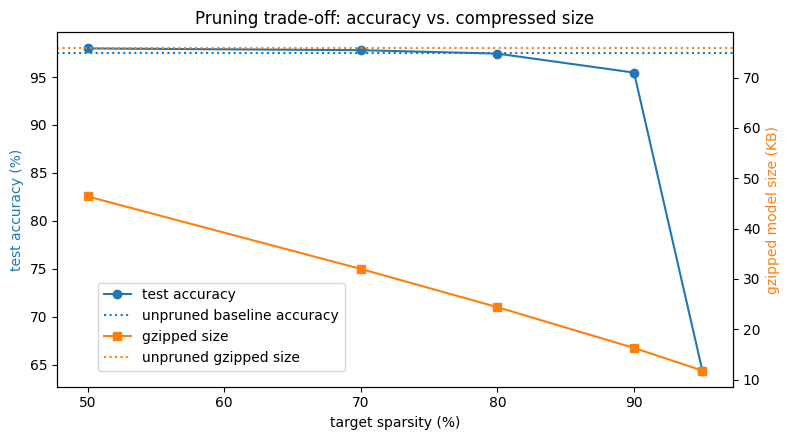

{'variant': 'Pruned 80% unstructured (float32 TFLite)', 'test accuracy': 0.9744, 'size (KB)': 82.9, 'gzipped (KB)': 24.4, 'weight sparsity': 0.8, 'latency (ms/image)': 0.0101}
Per-layer sparsity at 80%: {'conv2d_8/kernel:0': 0.7963, 'dense_8/kernel:0': 0.7999}


In [21]:
fig, ax1 = plt.subplots(figsize=(8, 4.5))
x = sweep_df["target sparsity"] * 100
ax1.plot(x, sweep_df["test accuracy"] * 100, marker="o", color="tab:blue", label="test accuracy")
ax1.axhline(baseline_accuracy * 100, color="tab:blue", linestyle=":", label="unpruned baseline accuracy")
ax1.set_xlabel("target sparsity (%)")
ax1.set_ylabel("test accuracy (%)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(x, sweep_df["gzipped (KB)"], marker="s", color="tab:orange", label="gzipped size")
ax2.axhline(baseline_gz, color="tab:orange", linestyle=":", label="unpruned gzipped size")
ax2.set_ylabel("gzipped model size (KB)", color="tab:orange")
fig.legend(loc="lower left", bbox_to_anchor=(0.12, 0.15))
plt.title("Pruning trade-off: accuracy vs. compressed size")
plt.tight_layout()
plt.show()

f = path("pruned_80_float32.tflite")
record("Pruned 80% unstructured (float32 TFLite)", "pruning",
       f, evaluate_tflite(f, test_images, test_labels), pruned_models[0.8])

print("Per-layer sparsity at 80%:", weight_sparsity(pruned_models[0.8])[1])

### B2. Pruning schedule: gradual vs. constant

`PolynomialDecay` ramps sparsity up gradually, giving the network time to adapt. `ConstantSparsity` jumps straight to the target. Both target 80% with the same training budget.

In [22]:
constant_80 = prune_and_train(tfmot.sparsity.keras.ConstantSparsity(target_sparsity=0.8, begin_step=0))
_, constant_stats = summarize_pruned(constant_80, "pruned_80_constant_float32.tflite")
_, poly_stats = summarize_pruned(pruned_models[0.8], "pruned_80_float32.tflite")
pd.DataFrame([{"schedule": "PolynomialDecay 0% -> 80%", **poly_stats},
              {"schedule": "ConstantSparsity 80%", **constant_stats}])

Epoch 1/2
422/422 - 2s - loss: 0.1517 - accuracy: 0.9612 - val_loss: 0.0998 - val_accuracy: 0.9745 - 2s/epoch - 5ms/step
Epoch 2/2
422/422 - 1s - loss: 0.1034 - accuracy: 0.9728 - val_loss: 0.0814 - val_accuracy: 0.9785 - 990ms/epoch - 2ms/step
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp9xg6gu6s\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp9xg6gu6s\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpzhfqzkk2\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmpzhfqzkk2\assets


,schedule,measured sparsity,test accuracy,gzipped (KB)
0,PolynomialDecay 0% -> 80%,0.8,0.9744,24.4
1,ConstantSparsity 80%,0.8,0.9719,24.5


### B3. Structured 2:4 pruning vs. unstructured

Unstructured pruning can zero *any* weight, which compresses well but doesn't speed up standard hardware. **2:4 structured sparsity** keeps at most 2 non-zero weights in every group of 4 consecutive weights. NVIDIA Ampere+ GPUs accelerate this pattern in hardware. It fixes sparsity at 50%, so it's compared with unstructured 50%.

In [23]:
def m_by_n_compliance(kernel, m=2, n=4):
    """Fraction of groups of n consecutive input weights (per output unit) with at most m non-zeros."""
    groups = kernel.T.reshape(kernel.shape[1], -1, n)
    return float(np.mean(np.count_nonzero(groups, axis=-1) <= m))


two_four = prune_and_train(m_by_n=(2, 4))
dense_kernel = next(l for l in two_four.layers if isinstance(l, keras.layers.Dense)).kernel.numpy()
f, two_four_stats = summarize_pruned(two_four, "pruned_2by4_float32.tflite")
_, unstructured_50 = summarize_pruned(pruned_models[0.5], "pruned_50_float32.tflite")

print(f"2:4 pattern satisfied by {m_by_n_compliance(dense_kernel):.1%} of groups in the Dense kernel")
record("Pruned 2:4 structured (float32 TFLite)", "pruning",
       f, evaluate_tflite(f, test_images, test_labels), two_four)
pd.DataFrame([{"pruning": "unstructured 50%", **unstructured_50},
              {"pruning": "structured 2:4 (Dense layer)", **two_four_stats}])

Epoch 1/2
422/422 - 2s - loss: 0.0660 - accuracy: 0.9815 - val_loss: 0.0476 - val_accuracy: 0.9887 - 2s/epoch - 5ms/step
Epoch 2/2
422/422 - 1s - loss: 0.0582 - accuracy: 0.9839 - val_loss: 0.0483 - val_accuracy: 0.9887 - 1s/epoch - 2ms/step
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp8sschn5d\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp8sschn5d\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp00zinhof\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp00zinhof\assets


2:4 pattern satisfied by 100.0% of groups in the Dense kernel
{'variant': 'Pruned 2:4 structured (float32 TFLite)', 'test accuracy': 0.9801, 'size (KB)': 82.9, 'gzipped (KB)': 47.7, 'weight sparsity': 0.497, 'latency (ms/image)': 0.0105}


,pruning,measured sparsity,test accuracy,gzipped (KB)
0,unstructured 50%,0.500,0.9798,46.4
1,structured 2:4 (Dense layer),0.497,0.9801,47.7


## C. Pruning + quantization: does the order matter?

The original lab pruned and then applied post-training quantization. A natural next step is to run QAT on the pruned model for better int8 accuracy, but **ordinary QAT updates every weight and silently destroys the sparsity**. TF-MOT's collaborative optimization offers **pruning-preserving QAT (PQAT)**, which keeps the zeros in place while learning int8 ranges.

All three start from the same 80%-pruned model and export integer-only int8. Watch the **weight sparsity** and **gzipped** columns.

In [24]:
pruned_80 = pruned_models[0.8]

# 1) Prune -> post-training quantization
f = convert_tflite(pruned_80, "prune_ptq_int8_io.tflite", "int8_io",
                   calibration_images=train_images, n_calibration=100)
record("Prune 80% -> PTQ int8", "pruning + quantization",
       f, evaluate_tflite(f, test_images, test_labels), pruned_80)

# 2) Prune -> ordinary QAT (1 epoch fine-tuning)
keras.utils.set_random_seed(SEED)
prune_qat = compile_model(quantize_model(copy_of(pruned_80)), learning_rate=1e-4)
prune_qat.fit(train_images, train_labels, epochs=1, shuffle=False, verbose=2)
f = convert_tflite(prune_qat, "prune_qat_int8_io.tflite", "int8_io")
record("Prune 80% -> QAT int8", "pruning + quantization",
       f, evaluate_tflite(f, test_images, test_labels), prune_qat)

# 3) Prune -> pruning-preserving QAT (PQAT)
keras.utils.set_random_seed(SEED)
annotated = tfmot.quantization.keras.quantize_annotate_model(copy_of(pruned_80))
pqat = tfmot.quantization.keras.quantize_apply(
    annotated, tfmot.experimental.combine.Default8BitPrunePreserveQuantizeScheme())
compile_model(pqat, learning_rate=1e-4)
pqat.fit(train_images, train_labels, epochs=1, shuffle=False, verbose=2)
f = convert_tflite(pqat, "prune_pqat_int8_io.tflite", "int8_io")
record("Prune 80% -> PQAT int8 (sparsity-preserving)", "pruning + quantization",
       f, evaluate_tflite(f, test_images, test_labels), pqat)

INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp0nxrx7wd\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp0nxrx7wd\assets
c:\MLOps\Labs\Model_Development\Quantization_and_Pruning\.venv\lib\site-packages\tensorflow\lite\python\convert.py:983: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


{'variant': 'Prune 80% -> PTQ int8', 'test accuracy': 0.9745, 'size (KB)': 24.1, 'gzipped (KB)': 8.6, 'weight sparsity': 0.8, 'latency (ms/image)': 0.0076}
1875/1875 - 5s - loss: 0.0811 - accuracy: 0.9790 - 5s/epoch - 3ms/step
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp4dy6mo3u\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmp4dy6mo3u\assets
c:\MLOps\Labs\Model_Development\Quantization_and_Pruning\.venv\lib\site-packages\tensorflow\lite\python\convert.py:983: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


{'variant': 'Prune 80% -> QAT int8', 'test accuracy': 0.9754, 'size (KB)': 24.2, 'gzipped (KB)': 10.1, 'weight sparsity': 0.446, 'latency (ms/image)': 0.0076}
1875/1875 - 4s - loss: 0.0837 - accuracy: 0.9780 - 4s/epoch - 2ms/step
INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmptfpxaeja\assets


INFO:tensorflow:Assets written to: C:\Users\NISHIT\AppData\Local\Temp\tmptfpxaeja\assets
c:\MLOps\Labs\Model_Development\Quantization_and_Pruning\.venv\lib\site-packages\tensorflow\lite\python\convert.py:983: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


{'variant': 'Prune 80% -> PQAT int8 (sparsity-preserving)', 'test accuracy': 0.9748, 'size (KB)': 24.2, 'gzipped (KB)': 8.2, 'weight sparsity': 0.8, 'latency (ms/image)': 0.0074}


## D. Results: every variant in one table

- **Compression** is based on gzipped size relative to the float32 TF Lite baseline, the fair basis because pruning only pays off after compression.
- **Latency** is the average time for one image on one CPU thread with the TF Lite interpreter on *this* machine. Desktop CPUs often run float models through highly optimized kernels, so int8 may not be faster here. The large speedups from integer models show up on edge hardware (phones, microcontrollers, NPUs), so treat these numbers as machine-specific.

In [25]:
results_df = pd.DataFrame(RESULTS)
results_df["compression vs float32 TFLite"] = (baseline_gz / results_df["gzipped (KB)"]).round(2)
results_df["accuracy change (pp)"] = ((results_df["test accuracy"] - baseline_accuracy) * 100).round(2)
pd.set_option("display.max_colwidth", 60)
results_df

,variant,group,test accuracy,size (KB),gzipped (KB),weight sparsity,latency (ms/image),compression vs float32 TFLite,accuracy change (pp)
0,Baseline (Keras .h5),baseline,0.9749,96.6,76.3,0.000,NaN,0.99,-0.00
1,Baseline (float32 TFLite),baseline,0.9749,82.9,75.8,0.000,0.0103,1.00,-0.00
2,PTQ dynamic-range int8 (original lab),post-training quantization,0.9749,23.7,18.8,0.000,0.0062,4.03,-0.00
3,PTQ float16,post-training quantization,0.9749,43.5,38.9,0.000,0.0105,1.95,-0.00
4,PTQ full-integer int8 (float I/O),post-training quantization,0.9748,24.4,18.8,0.000,0.0074,4.03,-0.01
5,PTQ integer-only int8 (int8 I/O),post-training quantization,0.9748,24.1,18.7,0.000,0.0074,4.05,-0.01
6,"QAT from initial weights, 1 epoch (original lab)",quantization-aware training,0.9615,24.2,17.6,0.000,0.0073,4.31,-1.34
7,"QAT fine-tuned from baseline, 1 epoch",quantization-aware training,0.9788,24.2,17.4,0.000,0.0076,4.36,0.39
8,Pruned 80% unstructured (float32 TFLite),pruning,0.9744,82.9,24.4,0.800,0.0101,3.11,-0.05
9,Pruned 2:4 structured (float32 TFLite),pruning,0.9801,82.9,47.7,0.497,0.0105,1.59,0.52


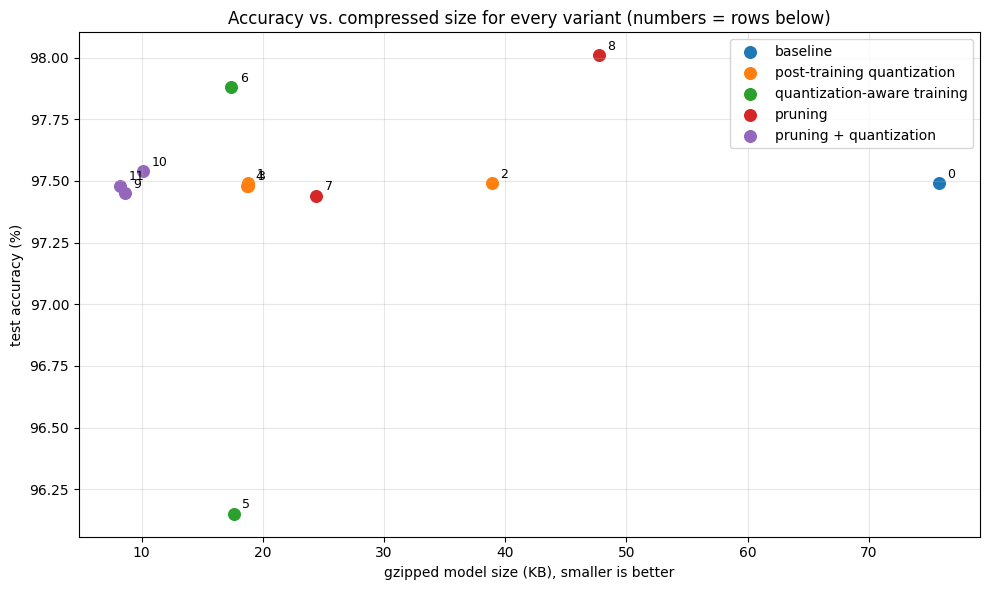

,variant,test accuracy,gzipped (KB)
0,Baseline (float32 TFLite),0.9749,75.8
1,PTQ dynamic-range int8 (original lab),0.9749,18.8
2,PTQ float16,0.9749,38.9
3,PTQ full-integer int8 (float I/O),0.9748,18.8
4,PTQ integer-only int8 (int8 I/O),0.9748,18.7
5,"QAT from initial weights, 1 epoch (original lab)",0.9615,17.6
6,"QAT fine-tuned from baseline, 1 epoch",0.9788,17.4
7,Pruned 80% unstructured (float32 TFLite),0.9744,24.4
8,Pruned 2:4 structured (float32 TFLite),0.9801,47.7
9,Prune 80% -> PTQ int8,0.9745,8.6


In [26]:
plot_df = results_df[results_df["variant"] != "Baseline (Keras .h5)"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 6))
for group, g in plot_df.groupby("group", sort=False):
    ax.scatter(g["gzipped (KB)"], g["test accuracy"] * 100, s=70, label=group)
for i, r in plot_df.iterrows():
    ax.annotate(str(i), (r["gzipped (KB)"], r["test accuracy"] * 100),
                textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xlabel("gzipped model size (KB), smaller is better")
ax.set_ylabel("test accuracy (%)")
ax.set_title("Accuracy vs. compressed size for every variant (numbers = rows below)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plot_df[["variant", "test accuracy", "gzipped (KB)"]]

In [27]:
# Key findings, computed from this run
r = results_df.set_index("variant")
within_1pp = results_df[results_df["accuracy change (pp)"] >= -1.0]
best = within_1pp.loc[within_1pp["gzipped (KB)"].idxmin()]
print(f"Smallest model within 1 percentage point of the baseline accuracy: {best['variant']}")
print(f"  {best['gzipped (KB)']} KB gzipped, {best['compression vs float32 TFLite']}x smaller, "
      f"accuracy {best['test accuracy']:.4f} ({best['accuracy change (pp)']:+.2f} pp)\n")

print("Integer-only int8, PTQ vs QAT fine-tuning (accuracy):",
      r.loc["PTQ integer-only int8 (int8 I/O)", "test accuracy"], "vs",
      r.loc["QAT fine-tuned from baseline, 1 epoch", "test accuracy"])
print("QAT from initial weights (original lab) vs QAT fine-tuned (accuracy):",
      r.loc["QAT from initial weights, 1 epoch (original lab)", "test accuracy"], "vs",
      r.loc["QAT fine-tuned from baseline, 1 epoch", "test accuracy"], "\n")

for v in ["Prune 80% -> PTQ int8", "Prune 80% -> QAT int8", "Prune 80% -> PQAT int8 (sparsity-preserving)"]:
    print(f"{v:48s} sparsity {r.loc[v, 'weight sparsity']:.3f}   gzipped {r.loc[v, 'gzipped (KB)']} KB   "
          f"accuracy {r.loc[v, 'test accuracy']:.4f}")

Smallest model within 1 percentage point of the baseline accuracy: Prune 80% -> PQAT int8 (sparsity-preserving)
  8.2 KB gzipped, 9.24x smaller, accuracy 0.9748 (-0.01 pp)

Integer-only int8, PTQ vs QAT fine-tuning (accuracy): 0.9748 vs 0.9788
QAT from initial weights (original lab) vs QAT fine-tuned (accuracy): 0.9615 vs 0.9788 

Prune 80% -> PTQ int8                            sparsity 0.800   gzipped 8.6 KB   accuracy 0.9745
Prune 80% -> QAT int8                            sparsity 0.446   gzipped 10.1 KB   accuracy 0.9754
Prune 80% -> PQAT int8 (sparsity-preserving)     sparsity 0.800   gzipped 8.2 KB   accuracy 0.9748


## Wrap up

This notebook compared the main model-optimization options for edge deployment on one model and one dataset:

- **Post-training quantization** ranges from dynamic-range (smaller file, float runtime still needed) to integer-only int8 (runs on integer-only hardware) and needs only a small calibration set.
- **Quantization-aware training** should fine-tune an already-trained model. Starting from scratch, as the original lab did, mixes up training quality with quantization effects.
- **Pruning** shrinks the *compressed* model as sparsity rises, until accuracy starts to fall. Structured 2:4 sparsity trades some flexibility for hardware speedups.
- **Combining** pruning with QAT needs the sparsity-preserving scheme, or the sparsity is lost.

Further reading:
* [Post-training quantization](https://www.tensorflow.org/lite/performance/post_training_quantization)
* [Quantization-aware training guide](https://www.tensorflow.org/model_optimization/guide/quantization/training_comprehensive_guide)
* [Pruning guide](https://www.tensorflow.org/model_optimization/guide/pruning/comprehensive_guide)
* [Collaborative optimization (PQAT)](https://www.tensorflow.org/model_optimization/guide/combine/collaborative_optimization)